<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI logo" width="180"></a>

# Resolve an image platform before counting its layers

An OCI index identifies several platform manifests. Choose one by architecture, verify its owning manifest and configuration through the real container worker, then measure how its declared compressed bytes are distributed across ordered layers. Compare manifest order with an analytical largest-first accumulation.

**Live public metadata at an immutable digest.** The index was resolved from Quay’s `prometheus/prometheus:v3.2.1` on 2026-11-14; the notebook uses the recorded SHA256 index digest, so a later tag movement does not redirect it. Only manifests and the small configuration blob are fetched. Image layer payloads are neither downloaded nor executed.

## Select the Linux architecture

`ARCHITECTURE` accepts **amd64** or **arm64**, default **amd64**. Both are present in the pinned index. The focused experiment selects **arm64**. Restart and run all after editing. This selects published metadata and does not emulate that architecture.

In [1]:
ARCHITECTURE = "amd64"

In [2]:
from datetime import datetime, timezone

import haybarn
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from notebook_support import PublicSources, finish, theme

STARTED_UTC = datetime.now(timezone.utc).isoformat(timespec="seconds")
public = PublicSources()
theme()
connection = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.displaycon = False
%config SqlMagic.feedback = 0
%sql connection
assert ARCHITECTURE in {"amd64", "arm64"}

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-software-packages/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-software-packages/notebooks/pyproject.toml.

## Attach the released container worker and resolve the index

The explicit release prefix selects the container worker rather than the package worker. The SQL returns descriptors from one pinned index. Their `size` is the **child manifest JSON size**, not the image payload size; layer byte totals are computed later.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'containers' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-software-packages@v0.2.0/vgi-containers-worker');
CREATE TABLE platforms AS SELECT * FROM containers.main.platforms('quay_public','prometheus/prometheus',
 'sha256:6927e0919a144aa7616fd0137d4816816d42f6b816de3af269ab065250859a62',max_results:=1000);
CREATE TABLE chosen AS SELECT * FROM platforms WHERE os='linux' AND architecture='{{ ARCHITECTURE }}';

,Count


In [4]:
%%sql inventory <<
SELECT os,architecture,variant,size AS manifest_json_bytes,index_digest,digest,observed_at FROM platforms
ORDER BY os,architecture,variant;

In [5]:
%%sql selected <<
SELECT digest,os,architecture,variant FROM chosen;

In [6]:
display(inventory)
assert len(selected) == 1, "Architecture must resolve to exactly one child manifest."
display(selected)
DIGEST = selected.iloc[0].digest
assert DIGEST.startswith("sha256:") and len(DIGEST) == 71

,os,architecture,variant,manifest_json_bytes,index_digest,digest,observed_at
0,linux,amd64,None,2407,sha256:6927e0919a144aa7616fd0137d4816816d42f6b...,sha256:5d34817348f69ddb956be509cafa4d4c2b5ecbb...,2026-11-14T09:42:35.728Z
1,linux,arm,v7,2407,sha256:6927e0919a144aa7616fd0137d4816816d42f6b...,sha256:b6f71b84c95f6bca0facd1598992f8f093059bb...,2026-11-14T09:42:35.728Z
2,linux,arm64,v8,2407,sha256:6927e0919a144aa7616fd0137d4816816d42f6b...,sha256:641f5faf625e3c667e2fb75b89a8a1dbc59a564...,2026-11-14T09:42:35.728Z
3,linux,ppc64le,None,2408,sha256:6927e0919a144aa7616fd0137d4816816d42f6b...,sha256:8a0b2df4e8409538813363957cefe8a452af4c0...,2026-11-14T09:42:35.728Z
4,linux,s390x,None,2408,sha256:6927e0919a144aa7616fd0137d4816816d42f6b...,sha256:1d37a8c172e96e0af0b90c13d4731be3134f819...,2026-11-14T09:42:35.728Z


,digest,os,architecture,variant
0,sha256:5d34817348f69ddb956be509cafa4d4c2b5ecbb...,linux,amd64,None


## Retrieve layers for the selected immutable manifest

This worker requires literal table-function arguments, so the folded bridge copies the single selected digest into a SQL template variable. Selection remains visible SQL, and the digest is displayed above. Both calls use that same digest. They are materialized before separate display queries to avoid repeated network requests.

The worker verifies manifest/configuration bytes against their SHA256 descriptors. Layer hashes and compressed sizes are reported from the manifest; **layer payload hashes are not verified** because payloads are not fetched. The configuration’s root filesystem entries provide a separate layer-count check.

In [7]:
%%sql
CREATE TABLE layers AS SELECT * FROM containers.main.layers('quay_public','prometheus/prometheus','{{ DIGEST }}',max_results:=1000);
CREATE TABLE image_config AS SELECT * FROM containers.main.configuration('quay_public','prometheus/prometheus','{{ DIGEST }}',max_results:=1000);
CREATE TABLE layer_sizes AS SELECT position,digest,size,media_type,size/1048576.0 AS size_mib,
 100.0*size/sum(size) OVER() AS percent_of_declared_bytes,
 row_number() OVER(ORDER BY size DESC,position) AS descending_size_rank FROM layers;
CREATE TABLE accumulation AS
SELECT position+1 AS layer_number,
 100.0*sum(size) OVER(ORDER BY position ROWS UNBOUNDED PRECEDING)/sum(size) OVER() AS cumulative_percent,
 'Manifest order' AS ordering FROM layer_sizes
UNION ALL
SELECT descending_size_rank,
 100.0*sum(size) OVER(ORDER BY descending_size_rank ROWS UNBOUNDED PRECEDING)/sum(size) OVER(),
 'Largest first (analysis only)' FROM layer_sizes;

,Count


In [8]:
%%sql descriptors <<
SELECT position,digest,size,size_mib,percent_of_declared_bytes,media_type FROM layer_sizes ORDER BY position;

In [9]:
%%sql totals <<
SELECT count(*) AS layer_count,sum(size) AS declared_bytes,sum(size)/1048576.0 AS declared_mib,
 max(size)/1048576.0 AS largest_mib,
 100.0*sum(size) FILTER(WHERE descending_size_rank<=2)/sum(size) AS top_two_percent
FROM layer_sizes;

,position,digest,size,size_mib,percent_of_declared_bytes,media_type
0,0,sha256:9fa9226be034e47923c0457d916aa68474cdfb2...,783033,0.746758,0.670540,application/vnd.docker.image.rootfs.diff.tar.gzip
1,1,sha256:1617e25568b2231fdd0d5caff63b06f6f7738d8...,480923,0.458644,0.411832,application/vnd.docker.image.rootfs.diff.tar.gzip
2,2,sha256:3488d0e317d1f67f7cb391d01b72762da99ec10...,60464347,57.663295,51.777815,application/vnd.docker.image.rootfs.diff.tar.gzip
3,3,sha256:e0d996230080b52e6b712ede21e29c93d66cc72...,54961657,52.415521,47.065661,application/vnd.docker.image.rootfs.diff.tar.gzip
4,4,sha256:5805cfa1a34ea3426e598e985eccd6771bec28e...,605,0.000577,0.000518,application/vnd.docker.image.rootfs.diff.tar.gzip
5,5,sha256:c8c5fe18afabf02c3458305a4cea70ca65f4442...,4023,0.003837,0.003445,application/vnd.docker.image.rootfs.diff.tar.gzip
6,6,sha256:34c169812ca7958c6f57b8149ec2bed389624dc...,1440,0.001373,0.001233,application/vnd.docker.image.rootfs.diff.tar.gzip
7,7,sha256:f5d2fa6280adb2c39ec4794f44255945479a884...,79767,0.076072,0.068307,application/vnd.docker.image.rootfs.diff.tar.gzip
8,8,sha256:0ff6b3eeee9461a26d6326d1ff4fca5a931b4e0...,100,0.000095,0.000086,application/vnd.docker.image.rootfs.diff.tar.gzip
9,9,sha256:4a3afe08a0ac6c24de3b4dc5f4653b0ca28af3d...,658,0.000628,0.000563,application/vnd.docker.image.rootfs.diff.tar.gzip


,layer_count,declared_bytes,declared_mib,largest_mib,top_two_percent
0,10,116776553.0,111.366799,57.663295,98.843476


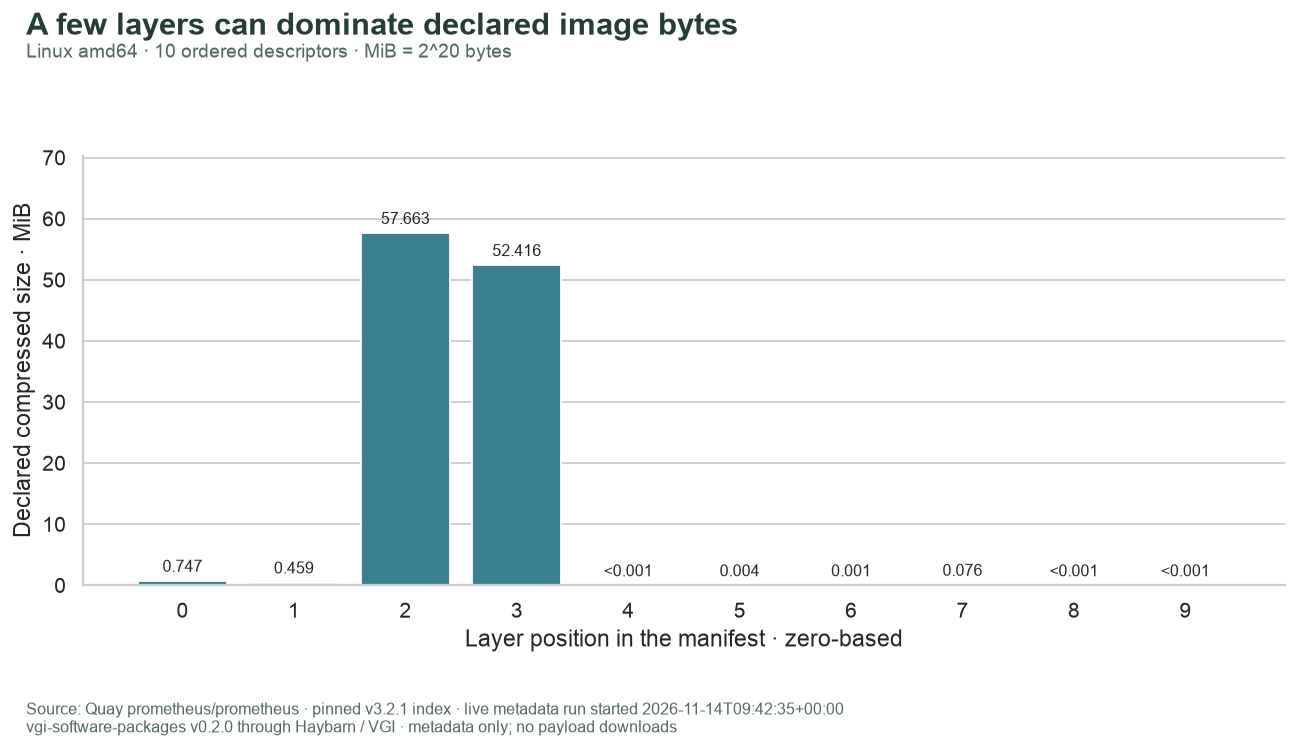

In [10]:
display(descriptors)
display(totals)
source = f"Source: Quay prometheus/prometheus · pinned v3.2.1 index · live metadata run started {STARTED_UTC}"
fig, ax = plt.subplots(figsize=(11, 5.8))
ax.bar(descriptors.position, descriptors.size_mib, color="#397f91")
for row in descriptors.itertuples():
    ax.annotate(
        ("<0.001" if 0 < row.size_mib < 0.001 else f"{row.size_mib:.3f}"),
        (row.position, row.size_mib),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=9,
    )
ax.set(
    xticks=descriptors.position,
    xlabel="Layer position in the manifest · zero-based",
    ylabel="Declared compressed size · MiB",
    ylim=(0, float(descriptors.size_mib.max()) * 1.22),
)
ax.grid(axis="x", visible=False)
finish(
    fig,
    f"layer-sizes-{ARCHITECTURE}",
    "A few layers can dominate declared image bytes",
    f"Linux {ARCHITECTURE} · {len(descriptors)} ordered descriptors · MiB = 2^20 bytes",
    source,
)

## Separate sequence from concentration

SQL accumulates the same bytes twice: once in manifest order, and once after sorting by size. The second curve measures concentration; it is **not** a proposed pull sequence or timing model. Actual downloads can be parallel, reuse cached blobs, include other metadata and incur protocol overhead. Descriptor byte totals are not an unpacked filesystem size.

In [11]:
%%sql curves <<
SELECT * FROM accumulation ORDER BY ordering,layer_number;

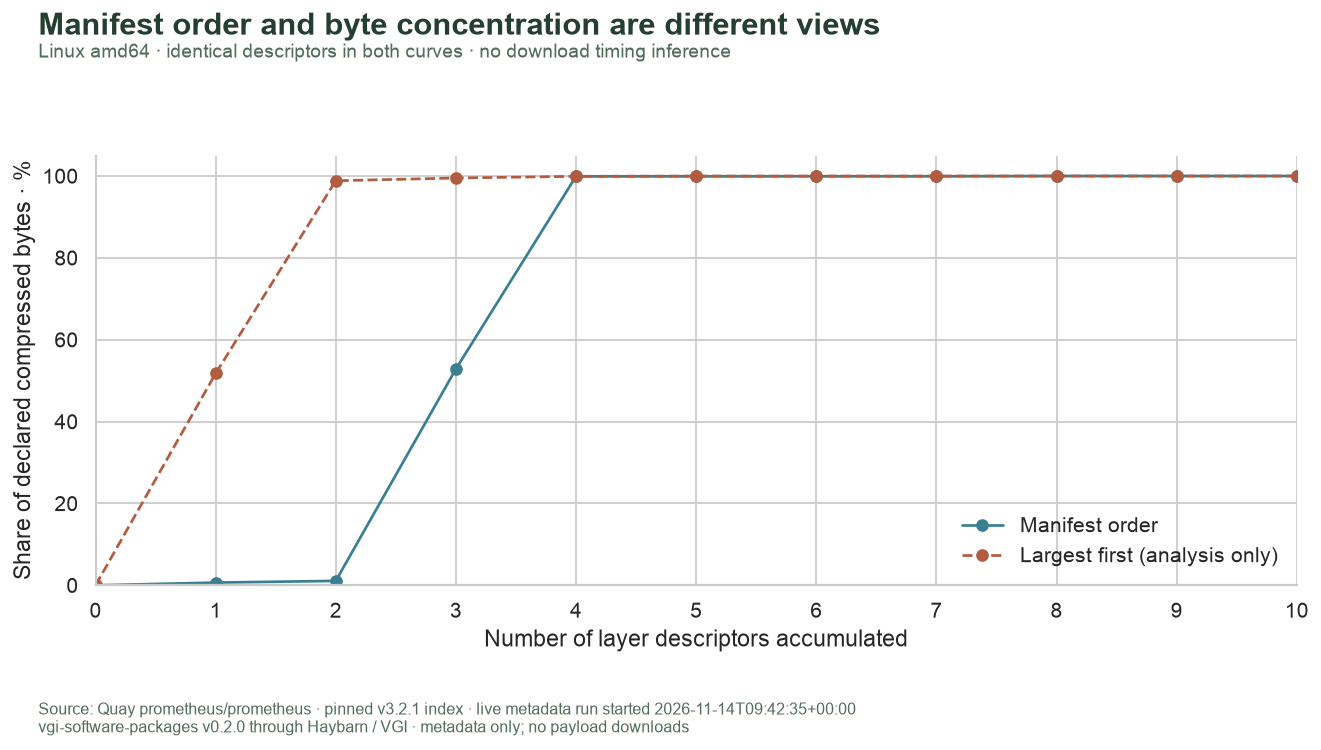

In [12]:
fig, ax = plt.subplots(figsize=(11, 5.8))
for ordering, color, style in [("Manifest order", "#397f91", "-"), ("Largest first (analysis only)", "#b25b3f", "--")]:
    frame = curves.loc[curves.ordering == ordering]
    ax.plot(
        np.r_[0, frame.layer_number], np.r_[0, frame.cumulative_percent], style, marker="o", color=color, label=ordering
    )
ax.set(
    xlabel="Number of layer descriptors accumulated",
    ylabel="Share of declared compressed bytes · %",
    xticks=range(len(descriptors) + 1),
    ylim=(0, 105),
    xlim=(0, len(descriptors)),
)
ax.legend(loc="lower right", frameon=False)
finish(
    fig,
    f"layer-concentration-{ARCHITECTURE}",
    "Manifest order and byte concentration are different views",
    f"Linux {ARCHITECTURE} · identical descriptors in both curves · no download timing inference",
    source,
)

In [13]:
row = totals.iloc[0]
display(
    Markdown(
        f"The selected **linux/{ARCHITECTURE}** manifest declares **{int(row.layer_count)} layers**, totaling "
        f"**{int(row.declared_bytes):,} compressed bytes ({row.declared_mib:.2f} MiB)**. "
        f"Its two largest descriptors account for **{row.top_two_percent:.2f}%** of that total. "
        "This is a metadata inventory. It does not include a payload integrity check, "
        "installed size, vulnerability assessment or startup benchmark."
    )
)

The selected **linux/amd64** manifest declares **10 layers**, totaling **116,776,553 compressed bytes (111.37 MiB)**. Its two largest descriptors account for **98.84%** of that total. This is a metadata inventory. It does not include a payload integrity check, installed size, vulnerability assessment or startup benchmark.

In [14]:
%%sql checks <<
SELECT 'platform retrieval did not hit its row limit' AS check_name,(SELECT count(*)>0 AND count(*)<1000 FROM platforms) AS passed
UNION ALL SELECT 'all descriptors belong to the pinned index',
 (SELECT bool_and(index_digest='sha256:6927e0919a144aa7616fd0137d4816816d42f6b816de3af269ab065250859a62') FROM platforms)
UNION ALL SELECT 'exactly one selected Linux architecture',(SELECT count(*)=1 AND bool_and(os='linux' AND architecture='{{ ARCHITECTURE }}') FROM chosen)
UNION ALL SELECT 'layer retrieval did not hit its row limit',(SELECT count(*)>0 AND count(*)<1000 FROM layers)
UNION ALL SELECT 'positions are unique and contiguous from zero',
 (SELECT count(*)=count(DISTINCT position) AND min(position)=0 AND max(position)=count(*)-1 FROM layers)
UNION ALL SELECT 'layers belong to the selected manifest',(SELECT bool_and(manifest_digest='{{ DIGEST }}') FROM layers)
UNION ALL SELECT 'layer sizes are present and nonnegative',(SELECT count(*)=count(size) AND min(size)>=0 AND sum(size)>0 FROM layers)
UNION ALL SELECT 'layer digests have SHA256 form',(SELECT bool_and(regexp_full_match(digest,'sha256:[0-9a-f]{64}')) FROM layers)
UNION ALL SELECT 'configuration identity agrees with selected manifest',
 (SELECT count(*)=1 AND bool_and(digest='{{ DIGEST }}' AND os='linux' AND architecture='{{ ARCHITECTURE }}') FROM image_config)
UNION ALL SELECT 'configuration rootfs entries agree with layer count',
 (SELECT json_array_length(metadata,'$.rootfs.diff_ids')=(SELECT count(*) FROM layers) FROM image_config)
UNION ALL SELECT 'MiB conversion reconciles with declared bytes',
 (SELECT bool_and(abs(size_mib*1048576-size)<0.5) FROM layer_sizes)
UNION ALL SELECT 'both cumulative curves end at one hundred percent',
 (SELECT count(*)=2 AND bool_and(abs(final_percent-100)<1e-9) FROM
 (SELECT ordering,max(cumulative_percent) AS final_percent FROM accumulation GROUP BY ordering));

In [15]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), checks

,check_name,passed
0,platform retrieval did not hit its row limit,True
1,all descriptors belong to the pinned index,True
2,exactly one selected Linux architecture,True
3,layer retrieval did not hit its row limit,True
4,positions are unique and contiguous from zero,True
5,layers belong to the selected manifest,True
6,layer sizes are present and nonnegative,True
7,layer digests have SHA256 form,True
8,configuration identity agrees with selected ma...,True
9,configuration rootfs entries agree with layer ...,True


## Focused experiment: select arm64

Change only **`ARCHITECTURE` from amd64 to arm64**, restart and run all. Predict a different child digest within the same pinned index. Compare the total declared compressed bytes, ordered size bars and two-layer concentration. Similar layer counts need not imply identical bytes or payloads.

The index and repository are fixed, but the selected image contents can differ by architecture; this is not a controlled performance benchmark. No image is run. Restore **amd64** for the saved baseline; the README command preserves it while executing the experiment separately.

In [16]:
connection.close()
public.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>